# ES (E-mini S&P 500): котировки по контрактам, ролловер и новости

Договорились начать с S&P 500, поэтому дальше смотрим фьючерс **ES** на CME. Горизонт тот же, один торговый день.

В ноутбуке три вопроса.

1. Откуда брать историю по каждому контракту ES, а не только склеенный ряд.
2. Как и когда Yahoo переключает `ES=F` с одного контракта на другой и как это проверить, если истёкших контрактов у Yahoo нет.
3. Какие новости могут объяснять дневное движение ES и где их взять с историей.

## 1. Что за контракт

- Базовый актив индекс S&P 500, множитель 50 долл. за пункт.
- Квартальные серии H (март), M (июнь), U (сентябрь), Z (декабрь).
- Последний торговый день третья пятница месяца контракта. Если пятница выходной, экспирация сдвигается раньше. Например, июньский контракт 2026 года истёк 18 июня, потому что 19 июня биржа закрыта (Juneteenth).
- Ролл по CME. На странице Equity Index Roll Dates биржа пишет, что для фондовых индексов дата ролла это **понедельник перед третьей пятницей**. С этого дня "ведущим" считается следующий контракт.

Даты с сайта CME, которые нам понадобятся.

| Контракт | Экспирация | Ролл CME |
|---|---|---|
| ESH25 | 2025-03-21 | 2025-03-17 |
| ESM25 | 2025-06-20 | 2025-06-16 |
| ESU25 | 2025-09-19 | 2025-09-15 |
| ESZ25 | 2025-12-19 | 2025-12-15 |
| ESH26 | 2026-03-20 | 2026-03-16 |
| ESM26 | 2026-06-18 | 2026-06-15 |
| ESU26 | 2026-09-18 | 2026-09-14 |
| ESZ26 | 2026-12-18 | 2026-12-14 |

Важная деталь. Часть брокеров и сайтов до сих пор пишет про ролл "за 8 дней до экспирации, в четверг". То есть единого правила у вендоров нет, и для `ES=F` его надо выяснять по данным.

## 2. Источники котировок по отдельным контрактам

| Источник | Отдельные контракты | Как склеивает | Доступ | Комментарий |
|---|---|---|---|---|
| Yahoo (`yfinance`) | только текущие торгующиеся | правило не описано | бесплатно | истёкших контрактов нет, это Александр уже показал на CL |
| Databento, датасет `GLBX.MDP3` | все, ES с 2010-06-06 | `ES.c.0` по календарю (переключение после экспирации), `ES.v.0` по объёму предыдущего дня, `ES.n.0` по open interest на закрытии предыдущего дня | платно, оплата по объёму | цены не корректируются, скачки на ролле остаются. Есть дневные бары и статистика с open interest |
| Interactive Brokers, TWS API | истёкшие только за последние 2 года | сами | нужен счёт | для 10 лет истории не подходит |
| CME DataMine | все | сами | платно | первоисточник |
| TradingView | можно посмотреть глазами | `ES1!`, есть опция back-adjust | без API | только для визуальной сверки |

Вывод по источникам.

- Бесплатно и с полной историей по каждому контракту ничего не нашлось.
- Самый подходящий вариант Databento. У него правило склейки явно описано, а значит его можно объяснить на защите. Надо посчитать, сколько стоит выгрузка дневных баров ES за 2015-2026 в их калькуляторе.
- Пока работаем с `ES=F` из Yahoo, но даты переключения вытаскиваем сами (ниже).

In [18]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from scipy import stats

START = "2015-01-01"
END = "2026-10-27"


def load_yahoo(ticker, start=START, end=END):
    df = yf.download(
        ticker,
        start=start,
        end=end,
        interval="1d",
        auto_adjust=False,
        progress=False,
        threads=False,
    )
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    return df


es = load_yahoo("ES=F")  # склеенный фьючерс
spx = load_yahoo("^GSPC")  # сам индекс
irx = load_yahoo("^IRX")  # доходность 13-недельных T-bills, в процентах

for name, d in [("ES=F", es), ("^GSPC", spx), ("^IRX", irx)]:
    print(
        f"{name:6} {len(d):5} строк  {d.index.min().date()} .. {d.index.max().date()}"
    )

ES=F    2972 строк  2015-01-02 .. 2026-10-26
^GSPC   2971 строк  2015-01-02 .. 2026-10-26
^IRX    2970 строк  2015-01-02 .. 2026-10-26


### Качество ряда `ES=F`

In [19]:
print(
    "Пропуски:\n", es[["Open", "High", "Low", "Close", "Volume"]].isna().sum(), sep=""
)
print("\nДубликаты дат:", es.index.duplicated().sum())
print("Дней с нулевым объёмом:", (es["Volume"] == 0).sum())
print("Close == Adj Close:", es["Close"].equals(es["Adj Close"]))

gaps = es.index.to_series().diff().dt.days
print("\nРазрывы больше 4 календарных дней:")
print(gaps[gaps > 4])

only_es = es.index.difference(spx.index)
only_spx = spx.index.difference(es.index)
print(f"\nДней есть в ES=F, нет в ^GSPC: {len(only_es)}")
print(f"Дней есть в ^GSPC, нет в ES=F: {len(only_spx)}")
print(only_es[:10].date, only_spx[:10].date)

Пропуски:
Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Дубликаты дат: 0
Дней с нулевым объёмом: 9
Close == Adj Close: True

Разрывы больше 4 календарных дней:
Series([], Name: Date, dtype: float64)

Дней есть в ES=F, нет в ^GSPC: 3
Дней есть в ^GSPC, нет в ES=F: 2
[datetime.date(2023, 11, 23) datetime.date(2025, 1, 9)
 datetime.date(2025, 7, 4)] [datetime.date(2016, 10, 10) datetime.date(2016, 11, 11)]


### Базис как способ увидеть ролл

Цена фьючерса примерно равна $F = S \cdot e^{(r-q)\tau}$, где $r$ ставка, $q$ дивидендная доходность индекса, $\tau$ время до экспирации.

Отсюда базис $F/S - 1 \approx (r-q)\tau$. Внутри одного контракта он плавно идёт к нулю к экспирации. В момент переключения на следующий контракт $\tau$ скачком растёт примерно на 0,25 года, и базис прыгает. Получается "пила", и зубья пилы показывают, когда Yahoo переключился.

Оговорка. Время закрытия дневного бара `ES=F` и `^GSPC` может не совпадать, поэтому базис шумный. Но скачок на ролле должен быть заметно больше шума.

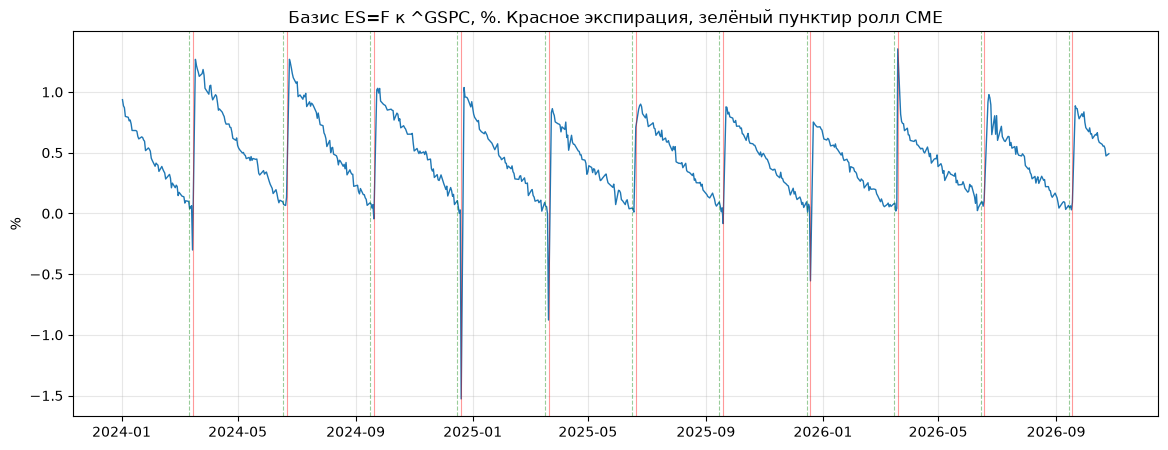

In [20]:
px = pd.DataFrame({"es": es["Close"], "spx": spx["Close"]}).dropna()
px["basis"] = px["es"] / px["spx"] - 1


def third_friday(year, month):
    d = pd.Timestamp(year, month, 1)
    first_friday = d + pd.Timedelta(days=(4 - d.weekday()) % 7)
    return first_friday + pd.Timedelta(weeks=2)


# Экспирации ES. Праздничные сдвиги правим руками
EXP_OVERRIDES = {(2026, 6): pd.Timestamp("2026-06-18")}
expirations = []
for y in range(2015, 2027):
    for m in (3, 6, 9, 12):
        expirations.append(EXP_OVERRIDES.get((y, m), third_friday(y, m)))
expirations = pd.DatetimeIndex(expirations)
expirations = expirations[
    (expirations >= px.index.min()) & (expirations <= px.index.max())
]
cme_roll = pd.DatetimeIndex(
    [third_friday(d.year, d.month) - pd.Timedelta(days=4) for d in expirations]
)

fig, ax = plt.subplots(figsize=(14, 5))
part = px.loc["2024-01-01":]
ax.plot(part.index, part["basis"] * 100, lw=1)
for d in expirations[expirations >= "2024-01-01"]:
    ax.axvline(d, color="red", alpha=0.4, lw=0.8)
for d in cme_roll[cme_roll >= "2024-01-01"]:
    ax.axvline(d, color="green", alpha=0.4, lw=0.8, ls="--")
ax.set_title("Базис ES=F к ^GSPC, %. Красное экспирация, зелёный пунктир ролл CME")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
plt.show()

### Какие отдельные контракты Yahoo вообще отдаёт

Для CL работал суффикс `.NYM`. Для ES биржа CME, пробуем `.CME`.

In [21]:
symbols = ["ESU25.CME", "ESZ25.CME", "ESU26.CME", "ESZ26.CME", "ESH27.CME", "ESM27.CME"]
contracts = {}
for s in symbols:
    try:
        d = load_yahoo(s, start="2026-06-01")
    except Exception as e:
        d = pd.DataFrame()
        print(s, type(e).__name__, e)
    contracts[s] = d
    print(
        f"{s}: {len(d)} строк",
        "" if d.empty else f"{d.index.min().date()} .. {d.index.max().date()}",
    )

$ESU25.CME: possibly delisted; no timezone found

1 Failed download:
['ESU25.CME']: possibly delisted; no timezone found


ESU25.CME: 0 строк 


$ESZ25.CME: possibly delisted; no timezone found

1 Failed download:
['ESZ25.CME']: possibly delisted; no timezone found
$ESU26.CME: possibly delisted; no timezone found

1 Failed download:
['ESU26.CME']: possibly delisted; no timezone found


ESZ25.CME: 0 строк 
ESU26.CME: 0 строк 
ESZ26.CME: 103 строк 2026-06-01 .. 2026-10-26
ESH27.CME: 103 строк 2026-06-01 .. 2026-10-26
ESM27.CME: 103 строк 2026-06-01 .. 2026-10-26


### Когда Yahoo переключился в сентябре 2026

Сентябрьский ESU26 уже истёк, его у Yahoo скорее всего нет. Зато есть декабрьский ESZ26. Ищем первый день, с которого `ES=F` совпадает с ESZ26.

In [22]:
z26 = contracts.get("ESZ26.CME", pd.DataFrame())
if z26.empty:
    print("ESZ26 не скачался, смотри формат тикера")
else:
    cmp_ = pd.DataFrame({"ES=F": es["Close"], "ESZ26": z26["Close"]}).dropna()
    cmp_["diff"] = cmp_["ES=F"] - cmp_["ESZ26"]
    cmp_["same"] = np.isclose(cmp_["diff"], 0, atol=0.01)
    print(cmp_.loc["2026-09-01":"2026-09-25"].round(2))
    first_same = cmp_.index[cmp_["same"]].min()
    print("\nES=F совпадает с ESZ26 начиная с", first_same.date())
    print("Ролл CME 2026-09-14, экспирация ESU26 2026-09-18")

               ES=F    ESZ26   diff   same
Date                                      
2026-09-01  7642.75  7709.50 -66.75  False
2026-09-02  7676.50  7743.50 -67.00  False
2026-09-03  7754.75  7822.00 -67.25  False
2026-09-04  7722.00  7789.25 -67.25  False
2026-09-08  7680.50  7747.25 -66.75  False
2026-09-09  7643.75  7709.50 -65.75  False
2026-09-10  7598.50  7664.50 -66.00  False
2026-09-11  7659.50  7727.25 -67.75  False
2026-09-14  7625.00  7692.75 -67.75  False
2026-09-15  7589.25  7656.00 -66.75  False
2026-09-16  7556.50  7623.00 -66.50  False
2026-09-17  7640.00  7707.25 -67.25  False
2026-09-18  7657.35  7712.50 -55.15  False
2026-09-21  7833.50  7833.50   0.00   True
2026-09-22  7831.75  7831.75   0.00   True
2026-09-23  7772.50  7772.50   0.00   True
2026-09-24  7767.00  7767.00   0.00   True
2026-09-25  7803.75  7803.75   0.00   True

ES=F совпадает с ESZ26 начиная с 2026-09-21
Ролл CME 2026-09-14, экспирация ESU26 2026-09-18


Вывод из таблицы. `ES=F` совпадает с ESZ26 с 21 сентября, то есть с **первого торгового дня после экспирации** ESU26. Ролл CME 14 сентября Yahoo не использует. По сути это календарный ролл по экспирации, как `ES.c.0` у Databento.

И ещё деталь. 18 сентября `ES=F = 7657.35`. Шаг цены ES 0,25, такой цены у фьючерса быть не может. Это финальный расчёт контракта по SOQ, то есть по утренней цене открытия индекса. Значит, в день экспирации Yahoo показывает расчётную цену истекающего контракта.

### Проверка правила на всей истории

Отдельных истёкших контрактов у Yahoo нет, поэтому проверяем правило через базис $b_t = \ln(F_t / S_t)$.

В день экспирации $F$ равна SOQ, а $S$ закрытию индекса, поэтому

$$b_{exp} \approx \ln\frac{S_{open}}{S_{close}}.$$

Это просто движение индекса за пятницу с открытия до закрытия. Отсюда острые выбросы на красных линиях графика. Ролл здесь ни при чём.

Сам скачок на новый контракт виден на следующий торговый день $d_1$. Если взять базис в последний день до экспирации $d_0$ и в $d_1$, эффект SOQ сокращается.

$$\Delta b = b_{d_1} - b_{d_0} \approx (r-q)(\tau_1 - \tau_0),$$

где $\tau_0$ время до экспирации старого контракта в $d_0$ (около дня), $\tau_1$ время до экспирации нового в $d_1$ (около 88 дней).

Две проверки.

1. В окне вокруг экспирации (кроме самого дня экспирации) самый большой $|\Delta b_t|$ должен приходиться на $d_1$. Не сработает только там, где $r \approx q$ и скачка почти нет.
2. $\Delta b / \Delta\tau = r - q$. Регрессия на ставку должна дать наклон около 1 и свободный член около $-q$, то есть примерно от $-1\%$ до $-2\%$ для S&P 500.

In [23]:
def next_expiration(exp):
    y, m = exp.year, exp.month + 3
    if m > 12:
        y, m = y + 1, m - 12
    return EXP_OVERRIDES.get((y, m), third_friday(y, m))


b = np.log(px["es"] / px["spx"])
resid = b.diff()  # равно r_es - r_spx

rows = []
for exp in expirations:
    before = px.index[px.index < exp]
    after = px.index[px.index > exp]
    if len(before) < 8 or len(after) < 3:
        continue
    d0, d1 = before[-1], after[0]
    tau0 = (exp - d0).days / 365
    tau1 = (next_expiration(exp) - d1).days / 365
    win = resid.loc[before[-8] : after[2]].drop(exp, errors="ignore")
    rows.append(
        {
            "expiration": exp.date(),
            "last_before": d0.date(),
            "switch": d1.date(),
            "soq_effect_pct": 100 * resid.get(exp, np.nan),
            "jump_pct": 100 * (b[d1] - b[d0]),
            "dtau": tau1 - tau0,
            "switch_is_max": win.abs().idxmax() == d1,
        }
    )
switches = pd.DataFrame(rows)
print(switches.round(3).to_string(index=False))
print(
    "\nДоля кварталов, где максимальный |остаток| вне дня экспирации "
    "приходится на день после неё:",
    switches["switch_is_max"].mean().round(2),
)

expiration last_before     switch  soq_effect_pct  jump_pct  dtau  switch_is_max
2015-03-20  2015-03-19 2015-03-23          -0.384    -0.519 0.238          False
2015-06-19  2015-06-18 2015-06-22           0.320    -0.560 0.238           True
2015-09-18  2015-09-17 2015-09-21           0.224    -0.079 0.238          False
2015-12-18  2015-12-17 2015-12-21           1.710     0.070 0.238           True
2016-03-18  2016-03-17 2016-03-21          -0.036    -0.391 0.238           True
2016-06-17  2016-06-16 2016-06-20           0.290    -0.494 0.238           True
2016-09-16  2016-09-15 2016-09-19           0.226    -0.181 0.238           True
2016-12-16  2016-12-15 2016-12-19           0.352    -0.177 0.238           True
2017-03-17  2017-03-16 2017-03-20           0.205    -0.193 0.238           True
2017-06-16  2017-06-15 2017-06-19          -0.049    -0.317 0.238           True
2017-09-15  2017-09-14 2017-09-18          -0.205    -0.080 0.238          False
2017-12-15  2017-12-14 2017-

OLS        наклон 1.14 ± 0.09, q = 1.48%, R^2 0.80
Theil-Sen  наклон 1.14, q = 1.56%


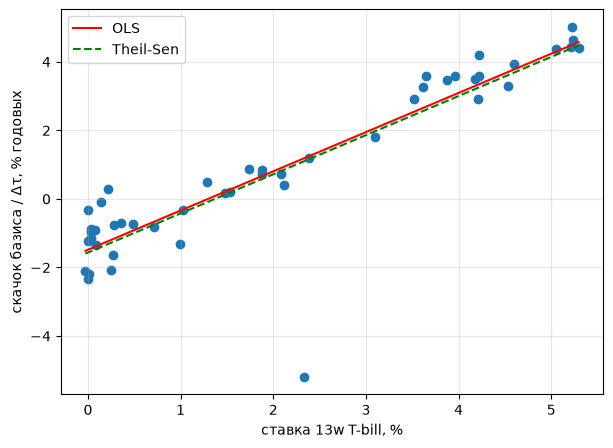

In [24]:
rate = irx["Close"].dropna() / 100
switches["r"] = rate.reindex(
    pd.to_datetime(switches["last_before"]), method="ffill"
).values
switches["carry"] = switches["jump_pct"] / 100 / switches["dtau"]
ok = switches.dropna(subset=["r", "carry"])

ols = stats.linregress(ok["r"], ok["carry"])
ts = stats.theilslopes(ok["carry"], ok["r"])
print(
    f"OLS        наклон {ols.slope:.2f} ± {ols.stderr:.2f}, "
    f"q = {-ols.intercept:.2%}, R^2 {ols.rvalue**2:.2f}"
)
print(f"Theil-Sen  наклон {ts[0]:.2f}, q = {-ts[1]:.2%}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ok["r"] * 100, ok["carry"] * 100)
xs = np.linspace(ok["r"].min(), ok["r"].max(), 10)
ax.plot(xs * 100, (ols.intercept + ols.slope * xs) * 100, color="red", label="OLS")
ax.plot(xs * 100, (ts[1] + ts[0] * xs) * 100, color="green", ls="--", label="Theil-Sen")
ax.set_xlabel("ставка 13w T-bill, %")
ax.set_ylabel("скачок базиса / Δτ, % годовых")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Theil-Sen добавлен из-за марта 2020 года. Базис тогда был очень шумным, и одна точка может сильно сдвинуть OLS.

### Таргет

Склеенный ряд без корректировки нельзя напрямую использовать для таргета. Портятся два дня в квартал.

- День экспирации. Доходность `ES=F` в этот день покрывает только движение до утреннего открытия, остаток дня теряется.
- Первый день после экспирации. В доходность входит скачок между контрактами, а не движение рынка. Это ровно та ошибка, которую Александр показал на CL.

Варианты.

1. Выкинуть эти дни из обучения и оценки. Это около 8 дней в год, потеря маленькая.
2. Сделать back-adjusted ряд. Для этого нужны цены обоих контрактов в день ролла, то есть Databento.

Пока берём вариант 1. Таргет `y_t = 1`, если лог-доходность `ES=F` за день t+1 больше нуля.

In [25]:
data = px.copy()
data["ret"] = np.log(data["es"]).diff()
roll_days = pd.to_datetime(switches["switch"]).tolist() + [
    e for e in expirations if e in data.index
]
data["is_switch"] = data.index.isin(roll_days)
data["ret_next"] = data["ret"].shift(-1)
data["switch_next"] = data["is_switch"].shift(-1, fill_value=False)
data["y"] = (data["ret_next"] > 0).astype("Int64")
data.loc[data["switch_next"] | data["ret_next"].isna(), "y"] = pd.NA

print(
    "Строк с таргетом:",
    data["y"].notna().sum(),
    " выкинуто дней:",
    data["switch_next"].sum(),
)
print("\nДоля роста по годам:")
print(data.groupby(data.index.year)["y"].mean().round(3))
print("\nВсего:", round(data["y"].mean(), 3))

Строк с таргетом: 2874  выкинуто дней: 94

Доля роста по годам:
Date
2015      0.5
2016    0.508
2017    0.572
2018    0.543
2019    0.578
2020    0.567
2021    0.594
2022    0.428
2023    0.541
2024    0.566
2025    0.558
2026     0.49
Name: y, dtype: Float64

Всего: 0.538


Классы немного несбалансированы. Константный прогноз "рост" уже даёт долю верных ответов, равную доле роста. Это первый бейзлайн, ниже него модель на новостях опускаться не должна.

In [26]:
out = Path("../data/02_intermediate")
out.mkdir(parents=True, exist_ok=True)
data.to_csv(out / "es_daily_target.csv")
switches.to_csv(out / "es_yahoo_roll_dates.csv", index=False)

## 3. Новости

### Почему новости должны что-то объяснять

ES это весь рынок акций США сразу. Отдельная новость про одну компанию его почти не двигает, если это не компания из верхушки индекса. Поэтому нас интересуют новости, которые меняют ожидания по всему рынку.

- **Макростатистика по расписанию.** CPI, Non-Farm Payrolls, ВВП, розничные продажи, PMI. Andersen, Bollerslev, Diebold и Vega (2007) показали, что неожиданная часть таких релизов сразу отражается во фьючерсах на фондовые индексы. Важна не сама цифра, а отклонение от консенсуса.
- **ФРС.** Решения FOMC в 14:00 по Нью-Йорку, пресс-конференции, выступления членов совета, протоколы.
- **Отчётности крупнейших компаний индекса.** У S&P 500 большой вес у нескольких мегакапов, их отчёты выходят после закрытия основной сессии и двигают ES ночью.
- **Политика и геополитика.** Тарифы, санкции, конфликты, нефть. Пример апрель 2025 и объявление тарифов.
- **Общий тон прессы.** Tetlock (2007) показал, что пессимизм в колонке WSJ предсказывает давление на цены с последующим разворотом.

Что из этого следует для нас.

- Нужны не все финансовые новости, а макро, ФРС, мегакапы и политика. Для отбора подойдут ключевые слова и тикеры.
- ES торгуется почти 23 часа в сутки. Отсечка новостей для дня t должна совпадать с закрытием дневного бара ES, а не с закрытием биржи акций в 16:00. Всё, что вышло после, относится к следующему дню. Иначе получим утечку будущего.
- Событие известно заранее (дата CPI или FOMC), а содержание нет. Значит полезный признак это "сегодня/завтра будет событие" плюс текст после события.

### Где брать новости

| Источник | Период | Что внутри | Доступ | Для чего |
|---|---|---|---|---|
| Alpaca News API (новости Benzinga) | с 2015 | в среднем 130+ статей в день, привязка к тикерам | нужен аккаунт Alpaca, проверить лимиты бесплатного плана | основной источник новостей |
| GDELT DOC 2.0 API | с 2017-01-01 | мировые СМИ, заголовки, ссылки, тон, число статей во времени | бесплатно, без ключа | объём новостей по теме, тон, фильтр по ключевым словам |
| FNSPID | 1999-2023 | 15,7 млн новостей по 4 775 компаниям S&P 500, выровнены с ценами, есть сентимент | открытый, GitHub и Hugging Face | готовый датасет, можно сразу посмотреть, как устроен |
| Kaggle "Daily News for Stock Market Prediction" | 2008-2016 | 25 заголовков в день из Reddit WorldNews, метка роста DJIA | открытый | учебный бейзлайн, близок к нашей постановке |
| Financial PhraseBank | без дат | предложения из финансовых новостей с разметкой тональности | открытый | обучить или проверить модель тональности |
| Сайт ФРС | всё время | заявления FOMC, протоколы, речи, точное время выхода | бесплатно | события с точным временем |

Для соцсетей (Reddit, X) вернёмся отдельно, по плану это февраль.

### Быстрая проверка на днях FOMC

Если новости важны, то в дни решений ФРС модуль доходности ES должен быть больше обычного. Даты решений взяты с сайта ФРС (внеплановое голосование 22 августа 2025 не берём).

In [27]:
fomc = pd.to_datetime(
    [
        "2024-01-31",
        "2024-03-20",
        "2024-05-01",
        "2024-06-12",
        "2024-07-31",
        "2024-09-18",
        "2024-11-07",
        "2024-12-18",
        "2025-01-29",
        "2025-03-19",
        "2025-05-07",
        "2025-06-18",
        "2025-07-30",
        "2025-09-17",
        "2025-10-29",
        "2025-12-10",
        "2026-01-28",
        "2026-03-18",
        "2026-04-29",
        "2026-06-17",
        "2026-07-29",
        "2026-09-16",
    ]
)

sample = data.loc["2024-01-01":, ["ret", "is_switch"]].dropna()
sample = sample[~sample["is_switch"]]
abs_ret = sample["ret"].abs()
is_fomc = sample.index.isin(fomc)
# решение в 14:00, но рынок часто двигается и на следующий день
is_fomc_next = sample.index.isin(fomc + pd.offsets.BDay(1))

for label, mask in [("день FOMC", is_fomc), ("день после FOMC", is_fomc_next)]:
    a, b = abs_ret[mask], abs_ret[~mask & ~is_fomc & ~is_fomc_next]
    u = stats.mannwhitneyu(a, b, alternative="greater")
    print(
        f"{label:16} n={len(a):2}  медиана |r| {100 * a.median():.2f}% против {100 * b.median():.2f}%  p={u.pvalue:.3f}"
    )

день FOMC        n=22  медиана |r| 0.56% против 0.48%  p=0.213
день после FOMC  n=20  медиана |r| 0.52% против 0.48%  p=0.206


### Объём новостей и волатильность (GDELT)

Берём из GDELT число статей в день по запросу про рынок и ФРС и смотрим, связано ли оно с модулем доходности ES в тот же и на следующий день. С направлением связи быть не должно, это проверка на здравый смысл.

GDELT просит не чаще одного запроса в 5 секунд, поэтому качаем по году, с паузой и кэшем в `data/01_raw/gdelt`. Если IP уже ограничен (у нас так было через VPN), ячейка остановится и следующая просто пропустит анализ.

In [ ]:
GDELT_URL = "https://api.gdeltproject.org/api/v2/doc/doc"
QUERY = (
    '("stock market" OR "Wall Street" OR "Federal Reserve" OR "S&P 500") '
    "sourcelang:english"
)
CACHE = Path("../data/01_raw/gdelt")
CACHE.mkdir(parents=True, exist_ok=True)


def gdelt_year(query, y, max_tries=4):
    path = CACHE / f"counts_{y}.csv"
    if path.exists():
        return pd.read_csv(path, parse_dates=["date"])
    params = {
        "query": query,
        "mode": "timelinevolraw",
        "format": "json",
        "startdatetime": f"{y}0101000000",
        "enddatetime": f"{y}1231235959",
        "timelinesmooth": 0,
    }
    wait = 15
    for _ in range(max_tries):
        resp = requests.get(GDELT_URL, params=params, timeout=60)
        if resp.status_code == 429:
            print(f"{y}: 429, жду {wait} с")
            time.sleep(wait)
            wait *= 2
            continue
        resp.raise_for_status()
        part = pd.DataFrame(resp.json()["timeline"][0]["data"])
        part["date"] = pd.to_datetime(part["date"], format="%Y%m%dT%H%M%SZ")
        part = part[["date", "value"]]
        part.to_csv(path, index=False)
        return part
    raise RuntimeError(f"{y}: GDELT не ответил за {max_tries} попыток")


def gdelt_daily_counts(query, start_year=2017, end_year=2026):
    parts = []
    for y in range(start_year, end_year + 1):
        try:
            part = gdelt_year(query, y)
            parts.append(part)
            print(y, len(part), "точек")
        except Exception as e:
            print(y, "ошибка:", type(e).__name__, str(e)[:200])
            if "429" in str(e) or "не ответил" in str(e):
                print("GDELT ограничил IP, остальные годы не запрашиваем")
                break
        time.sleep(10)
    if not parts:
        return pd.Series(dtype=float)
    df = pd.concat(parts)
    return df.groupby(df["date"].dt.normalize())["value"].sum()

news_cnt = pd.Series(dtype=float)  # GDELT ограничил IP, докачаем позже
#news_cnt = gdelt_daily_counts(QUERY)
print(news_cnt.describe())

In [ ]:
if news_cnt.empty:
    print("GDELT не ответил, пропускаем")
else:
    m = pd.DataFrame({"cnt": np.log1p(news_cnt)}).join(
        data[["ret", "ret_next", "is_switch"]], how="inner"
    )
    m = m[~m["is_switch"]].dropna()
    # убираем тренд роста самого GDELT: отклонение от скользящей медианы за 60 дней
    m["cnt_dev"] = m["cnt"] - m["cnt"].rolling(60, min_periods=20).median()
    m = m.dropna()

    for col, name in [
        ("ret", "|r| в тот же день"),
        ("ret_next", "|r| на следующий день"),
    ]:
        rho, p = stats.spearmanr(m["cnt_dev"], m[col].abs())
        print(f"объём новостей vs {name:22} rho={rho:.3f}  p={p:.3g}")
    rho, p = stats.spearmanr(m["cnt_dev"], m["ret_next"])
    print(
        f"объём новостей vs r на следующий день   rho={rho:.3f}  p={p:.3g}  (направление)"
    )

    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.plot(
        m.index,
        m["cnt_dev"].rolling(20).mean(),
        label="объём новостей, отклонение (20д)",
    )
    ax2 = ax1.twinx()
    ax2.plot(
        m.index,
        m["ret"].abs().rolling(20).mean() * 100,
        color="orange",
        label="|r| ES, % (20д)",
    )
    ax1.set_title("Объём новостей GDELT и волатильность ES")
    ax1.grid(alpha=0.3)
    fig.legend(loc="upper left")
    plt.show()

## 4. Итоги

Котировки
- Поконтрактной истории ES бесплатно нет. Yahoo отдаёт только торгующиеся контракты (ESZ26, ESH27, ESM27), истёкшие возвращают 404.
- Yahoo переключает `ES=F` на следующий контракт в первый торговый день после экспирации, а не в дату ролла CME. В день экспирации в `ES=F` стоит финальный расчёт по SOQ. Это видно напрямую на сентябре 2026 и подтверждается по базису на всей истории.
- Скачок базиса на ролле объясняется стоимостью переноса $(r-q)\Delta\tau$, это проверка того, что даты найдены верно.
- Для таргета выкидываем день экспирации и день после него, около 8 дней в год. Для честной склейки нужен Databento, надо оценить стоимость.
- Классы немного несбалансированы, константный бейзлайн "рост" надо будет обязательно показать на ЧП3.

Новости
- Для ES важны макро, ФРС, крупнейшие компании и политика, а не все подряд новости.
- Отсечку новостей надо привязать к закрытию бара ES.
- Основной кандидат Alpaca (Benzinga) с 2015 года, для объёма и тона GDELT с 2017 года, для примера готового датасета FNSPID.
- GDELT ограничивает частоту запросов по IP, для массового сбора нужен другой подход (их ngrams-датасет или запросы по коротким периодам с кэшем).